<b>Distribution of empty habitations per municipality</b>

**Author:** Thomas Giuri

**Project:**  Speculation Map (as part of the course "Big Data Analysis and Visualization" held at the University of Barcelona)

The purpose of this notebook is to create a map indicating the amount of empty habitations per municipality. For that we use a dataset containing the number of vacant dwellings declared by their holders subject to a direct tax on empty properties in the region of Catalonia. This tax is declared by the Government of Catalonia (Generalitat de Catalunya) and applies to the dwellings left vacant for at least two years without a valid reason. The dataset covers a taxation period going from 2018 to 2025.

In order to extract the density of vacant dwellings per municipalities and show it we first have to merge our dataset with the one used for plotting the map of Catalonia. After that we represent the density of habitations over catalan municipalities indipendently of the year recensed in the dataset. To focalise on a specific year it is then necessary to index the dataset with the corresponding year. We will select in that way the data for all the years recensed in the dataset.

Importing libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
import csv

Downloading the Map Dataset with all Catalan municipalities

In [2]:
df=gpd.read_file("../../Speculation-Map/Data/CatalunyaMapMunicipalities.json")

In [3]:
df

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,CODIPROV,NOMPROV,CAPPROV,geometry
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5..."
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((1.61829 41.76885, 1.61278 41.7..."
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((2.28512 41.51534, 2.28501 41.5..."
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((2.09411 42.14192, 2.09031 42.1..."
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((2.24126 41.70273, 2.24178 41.7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
942,439039,Camarles,Camarles,30.0157,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((0.6437 40.8212, 0.64239 40.821..."
943,439044,l'Aldea,l'Aldea,30.4743,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((0.60964 40.80699, 0.60855 40.8..."
944,439057,Salou,Salou,15.1248,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,43,Tarragona,Tarragona,"MULTIPOLYGON (((1.14208 41.09693, 1.13671 41.0..."
945,439060,l'Ampolla,l'Ampolla,35.6196,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((0.69184 40.85044, 0.69102 40.8..."


Showing the map of Catalunya per municipality

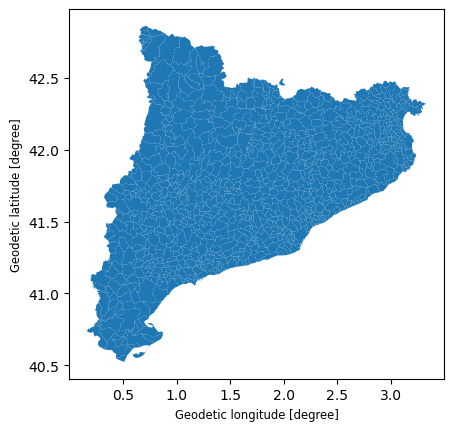

In [4]:
df.plot()
plt.show()

Uploading the dataset of empty habitations

In [5]:
dh=gpd.read_file("../../Speculation-Map/Data/EmptyBuildings/EmptyBuildings.csv")

In [6]:
dh['CODIMUNI'] = dh['Codi']
dh

,Any,Codi,Municipi,Exempt,Habitatges,Tenidor,Superfície útil,CODIMUNI
0,2018,080018,Abrera,No,3,2,"474,10",080018
1,2018,080039,Alella,No,2,2,"629,00",080039
2,2018,080057,"Ametlla del Vallès, l'",Sí,35,5,"6.354,78",080057
3,2018,080060,Arenys de Mar,No,22,5,"1.637,90",080060
4,2018,080076,Arenys de Munt,No,20,6,"2.914,77",080076
...,...,...,...,...,...,...,...,...
6038,2025,439044,"Aldea, l'",No,61,3,"2.649,71",439044
6039,2025,439057,Salou,No,14,11,"867,23",439057
6040,2025,439057,Salou,Sí,413,6,"21.886,53",439057
6041,2025,439076,"Canonja, la",No,2,2,"100,05",439076


Merging the two datasets in order to plot it into a unique map

In [7]:
df = df.merge(dh, on='CODIMUNI', how='left' )

In [8]:
df

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,...,NOMPROV,CAPPROV,geometry,Any,Codi,Municipi,Exempt,Habitatges,Tenidor,Superfície útil
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2018,080018,Abrera,No,3,2,"474,10"
1,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2019,080018,Abrera,No,3,2,"569,80"
2,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2020,080018,Abrera,No,4,3,"537,50"
3,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2020,080018,Abrera,Sí,1,1,"90,70"
4,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2021,080018,Abrera,No,3,2,"739,00"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5228,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2023,439076,"Canonja, la",No,4,2,"223,01"
5229,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2024,439076,"Canonja, la",No,3,3,"210,30"
5230,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2024,439076,"Canonja, la",Sí,13,3,"1.401,66"
5231,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2025,439076,"Canonja, la",No,2,2,"100,05"


In [9]:
totqls = df.groupby("CODIMUNI").agg(
    Hab=("Habitatges","sum")).reset_index()

In [10]:
totqls

,CODIMUNI,Hab
0,080018,33413142
1,080023,
2,080039,21332
3,080044,
4,080057,3531384644
...,...,...
942,439039,182928121197141
943,439044,50546261942238217111111561
944,439057,9339950431774153941939422304201342714413
945,439060,15811320262570


Making the final dataset to study and plot

In [11]:
df_final = df.merge(totqls, on='CODIMUNI', how = 'left', suffixes=("", "_total"))

In [12]:
df_final

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,...,CAPPROV,geometry,Any,Codi,Municipi,Exempt,Habitatges,Tenidor,Superfície útil,Hab
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2018,080018,Abrera,No,3,2,"474,10",33413142
1,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2019,080018,Abrera,No,3,2,"569,80",33413142
2,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2020,080018,Abrera,No,4,3,"537,50",33413142
3,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2020,080018,Abrera,Sí,1,1,"90,70",33413142
4,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2021,080018,Abrera,No,3,2,"739,00",33413142
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5228,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2023,439076,"Canonja, la",No,4,2,"223,01",11268173334313214
5229,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2024,439076,"Canonja, la",No,3,3,"210,30",11268173334313214
5230,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2024,439076,"Canonja, la",Sí,13,3,"1.401,66",11268173334313214
5231,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2025,439076,"Canonja, la",No,2,2,"100,05",11268173334313214


Plotting the distribution of empty habitations in Catalonia

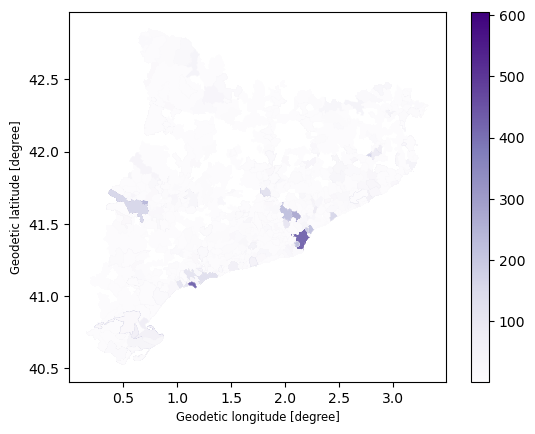

In [13]:
df_final['Habitatges']=pd.DataFrame.astype(df_final['Habitatges'],dtype='float')
df_final.plot(column='Habitatges',legend=True, cmap='Purples') 
plt.show()

Getting rid of the empty values of the hab column in order to
plot it

In [14]:
Hab=df_final['Hab']

In [15]:
idb=Hab==''

In [16]:
sum(idb)

193

In [17]:
Hab[idb]='0'

In [18]:
sum(Hab=='0')

193

In [19]:
df_final['Hab']=Hab

Changing the values of the 'Hab' column from strings to floats

In [20]:
df_final['Hab']=pd.DataFrame.astype(df_final['Hab'],dtype='float')

In [21]:
type(df_final['Hab'][3])

numpy.float64

Plotting the Hab column

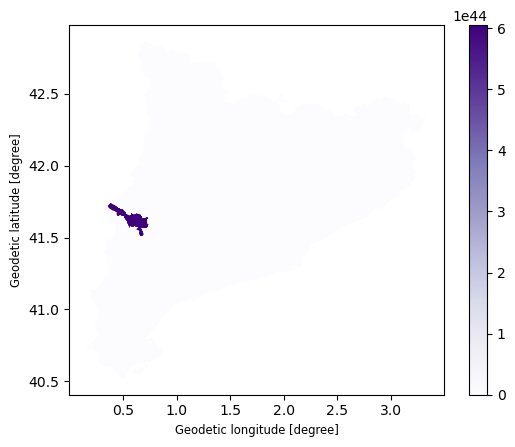

In [22]:
df_final.plot(column='Hab',legend=True,cmap='Purples')
plt.show()

Making a dataframe containing only the column of empty habitations and the Hab Column

In [23]:
dg=df_final[['CODIMUNI','Habitatges','Hab']]
dg

,CODIMUNI,Habitatges,Hab
0,080018,3.0,3.341314e+07
1,080018,3.0,3.341314e+07
2,080018,4.0,3.341314e+07
3,080018,1.0,3.341314e+07
4,080018,3.0,3.341314e+07
...,...,...,...
5228,439076,4.0,1.126817e+16
5229,439076,3.0,1.126817e+16
5230,439076,13.0,1.126817e+16
5231,439076,2.0,1.126817e+16


Plotting the dataset without the 'Hab' column

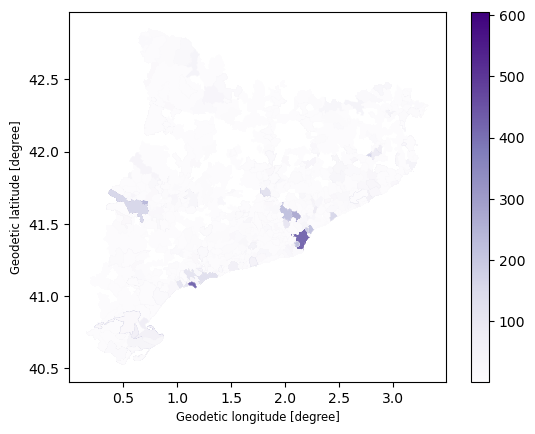

In [24]:
df['Habitatges']=pd.DataFrame.astype(df['Habitatges'],dtype='float')
df.plot(column='Habitatges',legend=True, cmap='Purples') 
plt.show()

Selecting and showing the data for 2018

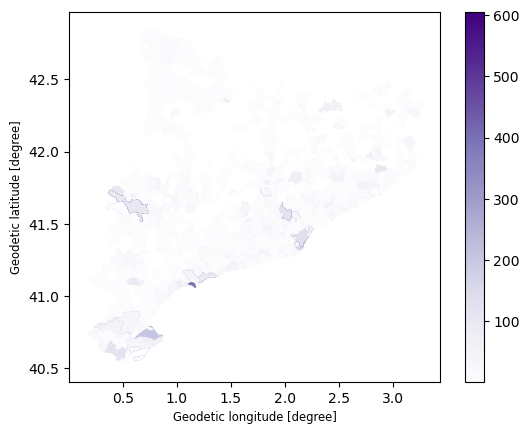

In [25]:
df_2018=df_final[df_final['Any']=='2018'].copy()
df_2018.plot(column='Habitatges',legend=True, cmap='Purples') 
plt.show()

Selecting and showing the data for 2019

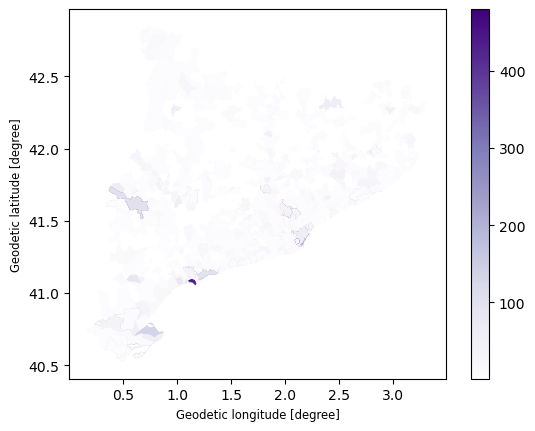

In [26]:
df_2019=df_final[df_final['Any']=='2019'].copy()
df_2019.plot(column='Habitatges',legend=True, cmap='Purples') 
plt.show()

Selecting and showing the data for 2020

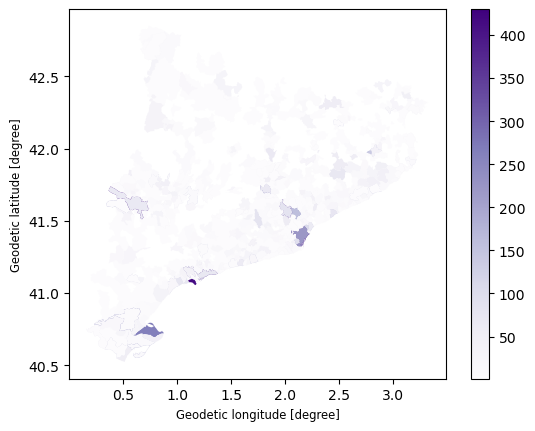

In [27]:
df_2020=df_final[df_final['Any']=='2020'].copy()
df_2020.plot(column='Habitatges',legend=True, cmap='Purples') 
plt.show()

Selecting and showing the data for 2021

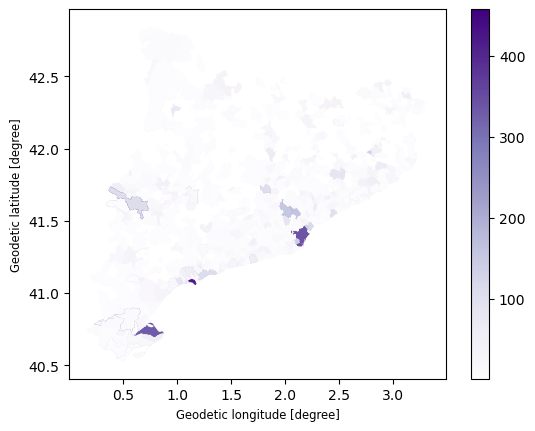

In [28]:
df_2021=df_final[df_final['Any']=='2021'].copy()
df_2021.plot(column='Habitatges',legend=True, cmap='Purples') 
plt.show()

Selecting and showing the data for 2022

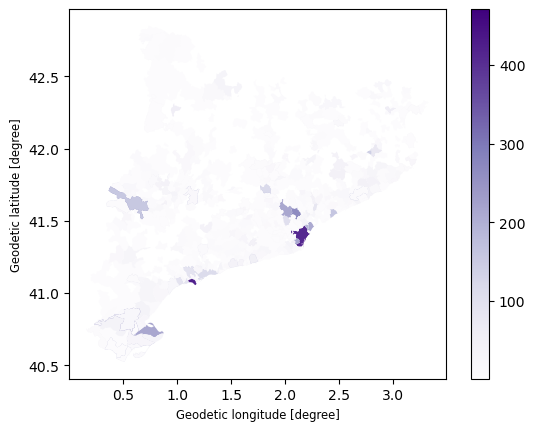

In [29]:
df_2022=df_final[df_final['Any']=='2022'].copy()
df_2022.plot(column='Habitatges',legend=True, cmap='Purples') 
plt.show()

Selecting and showing the data for 2023

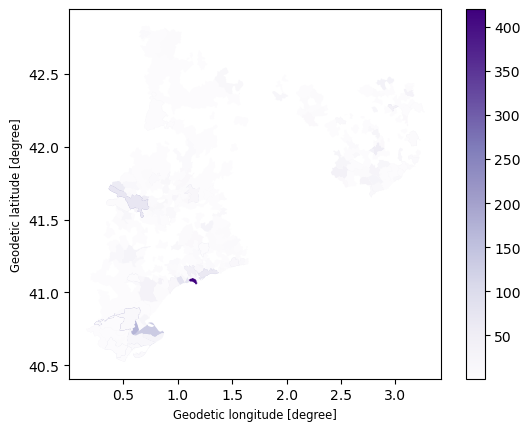

In [30]:
df_2023=df_final[df_final['Any']=='2023'].copy()
df_2023.plot(column='Habitatges',legend=True, cmap='Purples') 
plt.show()

Selecting and showing the data for 2024

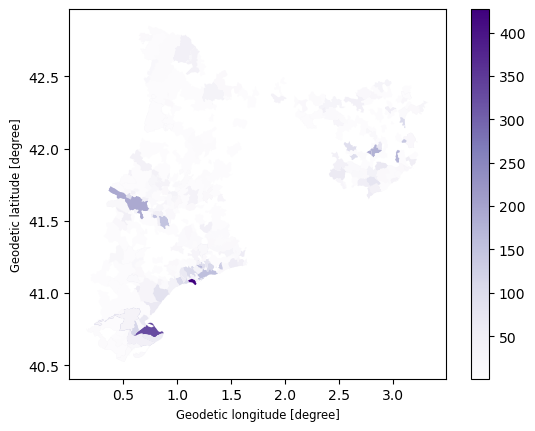

In [31]:
df_2024=df_final[df_final['Any']=='2024'].copy()
df_2024.plot(column='Habitatges',legend=True, cmap='Purples') 
plt.show()

Selecting and showing the data for 2025

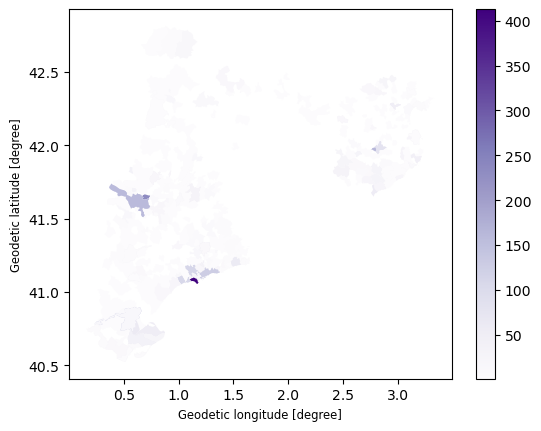

In [32]:
df_2025=df_final[df_final['Any']=='2025'].copy()
df_2025.plot(column='Habitatges',legend=True, cmap='Purples') 
plt.show()

Map of number of empty dwellings per habitant in each municipality

In [33]:
ruta_pob = "../Data/BuildingsAvailable/poblacio_codis.xlsx"
df_pob = pd.read_excel(ruta_pob, sheet_name="Dades", skiprows=1, dtype={0: str})  # Read 'Dades' sheet forcing 1st column as string to keep leading zeros
df_pob = df_pob.rename(columns={df_pob.columns[0]: "Codi", df_pob.columns[1]: "Any"})  # Rename first two columns
df_pob["Codi"] = df_pob["Codi"].ffill().str.strip().str.zfill(6)  # Forward-fill municipal code and ensure 6 digits
df_pob = df_pob[df_pob["Codi"].str.match(r"^\d{6}$")].copy()  # Keep only valid 6-digit numeric codes (drops 'TOTAL' and footer notes)
df_pob["Any"] = df_pob["Any"].astype(int)  # Convert year to integer
df_pob["Poblacio"] = pd.to_numeric(df_pob["Total"], errors="coerce")
df_pob

,Codi,Any,Homes,Dones,Total,Poblacio
0,250019,2021,90,85,175,175.0
1,250019,2011,95,77,172,172.0
2,250019,2001,98,81,179,179.0
3,250019,1991,85,79,164,164.0
4,250019,1981,92,92,184,184.0
...,...,...,...,...,...,...
4775,430521,2021,570,585,1155,1155.0
4776,430521,2011,625,646,1271,1271.0
4777,430521,2001,592,618,1210,1210.0
4778,430521,1991,609,639,1248,1248.0


In [34]:
df_pob['CODIMUNI']=df_pob['Codi']

In [35]:
df_final=df_final.merge(df_pob,on='CODIMUNI',how='left')
df_final

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,...,Habitatges,Tenidor,Superfície útil,Hab,Codi_y,Any_y,Homes,Dones,Total,Poblacio
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,3.0,2,"474,10",3.341314e+07,080018,2021,6369,6243,12612,12612.0
1,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,3.0,2,"474,10",3.341314e+07,080018,2011,6058,5757,11815,11815.0
2,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,3.0,2,"474,10",3.341314e+07,080018,2001,4430,4194,8624,8624.0
3,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,3.0,2,"474,10",3.341314e+07,080018,1991,2810,2654,5464,5464.0
4,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,3.0,2,"474,10",3.341314e+07,080018,1981,2162,2059,4221,4221.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26160,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,14.0,4,"868,81",1.126817e+16,439076,2021,2908,3063,5971,5971.0
26161,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,14.0,4,"868,81",1.126817e+16,439076,2011,2860,2848,5708,5708.0
26162,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,14.0,4,"868,81",1.126817e+16,439076,2001,..,..,..,NaN
26163,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,14.0,4,"868,81",1.126817e+16,439076,1991,..,..,..,NaN


Data for 2021

In [76]:
df_ds_2021=df_final[df_final['Any_y']==2021].copy()

In [77]:
df_ds_2021

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,...,Habitatges,Tenidor,Superfície útil,Hab,Codi_y,Any_y,Homes,Dones,Total,Poblacio
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,3.0,2,"474,10",3.341314e+07,080018,2021,6369,6243,12612,12612.0
5,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,3.0,2,"569,80",3.341314e+07,080018,2021,6369,6243,12612,12612.0
10,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,4.0,3,"537,50",3.341314e+07,080018,2021,6369,6243,12612,12612.0
15,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,1.0,1,"90,70",3.341314e+07,080018,2021,6369,6243,12612,12612.0
20,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,3.0,2,"739,00",3.341314e+07,080018,2021,6369,6243,12612,12612.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26140,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,4.0,2,"223,01",1.126817e+16,439076,2021,2908,3063,5971,5971.0
26145,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,3.0,3,"210,30",1.126817e+16,439076,2021,2908,3063,5971,5971.0
26150,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,13.0,3,"1.401,66",1.126817e+16,439076,2021,2908,3063,5971,5971.0
26155,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,2.0,2,"100,05",1.126817e+16,439076,2021,2908,3063,5971,5971.0


In [78]:
df_ds_2021['Habitatges']=pd.DataFrame.astype(df_ds_2021['Habitatges'],dtype='float')
df_ds_2021['Poblacio']=pd.DataFrame.astype(df_ds_2021['Poblacio'],dtype='float')

In [79]:
df_ds_2021['Buits_per_Hab']=df_ds_2021['Habitatges']/df_ds_2021['Poblacio']
df_ds_2021

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,...,Tenidor,Superfície útil,Hab,Codi_y,Any_y,Homes,Dones,Total,Poblacio,Buits_per_Hab
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,2,"474,10",3.341314e+07,080018,2021,6369,6243,12612,12612.0,0.000238
5,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,2,"569,80",3.341314e+07,080018,2021,6369,6243,12612,12612.0,0.000238
10,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,3,"537,50",3.341314e+07,080018,2021,6369,6243,12612,12612.0,0.000317
15,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,1,"90,70",3.341314e+07,080018,2021,6369,6243,12612,12612.0,0.000079
20,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,2,"739,00",3.341314e+07,080018,2021,6369,6243,12612,12612.0,0.000238
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26140,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,2,"223,01",1.126817e+16,439076,2021,2908,3063,5971,5971.0,0.000670
26145,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,3,"210,30",1.126817e+16,439076,2021,2908,3063,5971,5971.0,0.000502
26150,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,3,"1.401,66",1.126817e+16,439076,2021,2908,3063,5971,5971.0,0.002177
26155,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,2,"100,05",1.126817e+16,439076,2021,2908,3063,5971,5971.0,0.000335


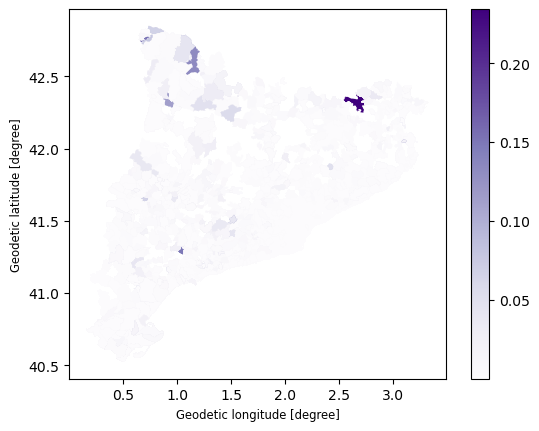

In [80]:
df_ds_2021.plot(column='Buits_per_Hab',legend=True,cmap='Purples')
plt.show()